# LAB 08 — Fine-tuning pretrained Transformer (DistilBERT) trên IMDb

Code lõi nằm ở `pretrained_classification.py`. Notebook này chạy:

1. dữ liệu IMDb (chia giống LAB 05–07), độ dài review tính bằng token;
2. **Exp 1** — Transformer from scratch so với DistilBERT fine-tuning (3 seed mỗi model);
3. **Exp 2** — frozen encoder (chỉ train head) so với fine-tuning;
4. **Exp 3** — 10 / 25 / 50 / 100% training data (pretrained, frozen, from scratch);
5. **Exp 4** — max length 64 / 128 / 256;
6. **Exp 5** — domain shift: train IMDb, test Yelp và Amazon;
7. application (metrics + confusion matrix), confidence analysis, error analysis.

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
warnings.filterwarnings("ignore")
import time, gc
from matplotlib.ticker import NullLocator
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import confusion_matrix
import transformers; transformers.logging.set_verbosity_error()
import pretrained_classification as pc
os.makedirs("images", exist_ok=True)
QUICK = os.environ.get("LAB8_QUICK") == "1"          # chạy thử nhanh trên dữ liệu nhỏ
if os.environ.get("LAB8_LOG"):                       # ghi thêm mọi dòng print ra file để theo dõi tiến độ
    import builtins
    _print = builtins.print
    def _tee(*a, **k):
        _print(*a, **k)
        with open(os.environ["LAB8_LOG"], "a", encoding="utf-8") as f:
            f.write(time.strftime("%H:%M:%S ") + " ".join(map(str, a)) + "\n")
    builtins.print = _tee
SEEDS = [42, 43, 44]
print("torch", torch.__version__, "| transformers", transformers.__version__, "|", pc.DEVICE,
      torch.cuda.get_device_name() if torch.cuda.is_available() else "")

RESULTS = []
def log(exp, setting, metric, value):
    RESULTS.append({"experiment": exp, "setting": setting, "metric": metric, "value": value})

torch 2.6.0+cu124 | transformers 5.17.0 | cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Dữ liệu

Train 19 923 / validation 4 981 (bỏ review trùng, chia stratified, seed 42) / test 25 000, giống LAB 05–07. Văn bản chỉ bỏ thẻ `<br />`; còn lại do tokenizer của DistilBERT xử lý (WordPiece, chữ thường).

In [2]:
data = pc.load_imdb()
if QUICK:
    data = {k: d.sample(n, random_state=0).reset_index(drop=True) for (k, d), n in zip(data.items(), [2000, 500, 1000])}
tokenizer = pc.get_tokenizer()
t0 = time.time()
ids = {k: pc.encode(tokenizer, d.text) for k, d in data.items()}
y = {k: d.label.values for k, d in data.items()}
print({k: len(v) for k, v in ids.items()}, f"| tokenize {time.time() - t0:.0f}s")
print("tỉ lệ positive:", {k: round(v.mean(), 3) for k, v in y.items()})

{'train': 19923, 'val': 4981, 'test': 25000} | tokenize 8s
tỉ lệ positive: {'train': np.float64(0.501), 'val': np.float64(0.501), 'test': np.float64(0.5)}


In [3]:
n_tok = np.array([len(x) for x in ids["train"]])       # đã cắt ở 512
n_word = data["train"].text.str.split().map(len).values
print(f"word / review: median {np.median(n_word):.0f}, mean {n_word.mean():.0f}")
print(f"token / review (có [CLS], [SEP], cắt ở 512): median {np.median(n_tok):.0f}, mean {n_tok.mean():.0f}")
print(f"token / word ≈ {np.median(n_tok / n_word):.2f}")
for T in [64, 128, 256, 512]:
    print(f"T = {T:3}: {np.mean(n_tok > T):.1%} review bị cắt")
    log("data", f"T={T}", "fraction truncated", float(np.mean(n_tok > T)))

word / review: median 172, mean 231
token / review (có [CLS], [SEP], cắt ở 512): median 221, mean 265
token / word ≈ 1.26
T =  64: 97.9% review bị cắt
T = 128: 87.8% review bị cắt
T = 256: 41.2% review bị cắt
T = 512: 0.0% review bị cắt


## 2. Hàm chạy thí nghiệm

- **Pretrained (fine-tuning):** DistilBERT + head [CLS] → Linear. AdamW lr 2e-5, weight decay 0.01, warmup 6% rồi giảm tuyến tính, batch 16, 2 epoch, bf16 autocast.
- **From scratch:** cấu hình LAB 07 (d_model 128, 4 head, d_ff 256, 1 layer, mean pooling trên token thật) nhưng dùng **cùng tokenizer và cùng max length** với model pretrained. AdamW lr 1e-3, batch 64, 6 epoch.
- Cả hai: clip gradient 1.0, chọn epoch có validation loss thấp nhất, đánh giá trên toàn bộ 25 000 review test.
- Như LAB 07, lỗi CUDA chập chờn của GPU này → train lại từ đầu với cùng seed; bước có gradient NaN → bỏ qua (đếm trong `skipped_steps`).

In [4]:
FT = dict(epochs=2, bs=16, lr=2e-5)
SCRATCH = dict(epochs=6, bs=64, lr=1e-3)
N_TRAIN = len(ids["train"])
perm = np.random.default_rng(pc.SEED).permutation(N_TRAIN)      # subset lồng nhau: 10% ⊂ 25% ⊂ 50% ⊂ 100%
def subset(frac):
    return np.sort(perm[: int(round(frac * N_TRAIN))])

def run(kind, seed=42, frac=1.0, T=256, keep=False):
    for attempt in range(3):
        try:
            return _run(kind, seed, frac, T, keep)
        except RuntimeError as e:
            if not any(s in str(e) for s in ("CUDA", "cuDNN", "CUBLAS", "cublas")):
                raise
            print(f"  [lỗi GPU: {str(e)[:60]}… → train lại]")
            log("GPU retries", f"{kind} seed={seed} frac={frac} T={T}", "retry", attempt + 1)
            gc.collect(); torch.cuda.empty_cache()
    raise RuntimeError("GPU lỗi 3 lần liên tiếp")

def _run(kind, seed, frac, T, keep):
    pc.set_seed(seed)
    model = pc.PretrainedClassifier() if kind == "pretrained" else pc.ScratchTransformer(tokenizer.vocab_size, max_len=512)
    cfg = FT if kind == "pretrained" else SCRATCH
    idx = subset(frac)
    tr_ids, tr_y = [ids["train"][i] for i in idx], y["train"][idx]
    print(f"{kind} | seed {seed} | {frac:.0%} train ({len(idx)}) | T = {T}")
    hist, info = pc.train_model(model, tr_ids, tr_y, ids["val"], y["val"], max_len=T, seed=seed, **cfg)
    t0 = time.time()
    p = pc.predict_proba(model, ids["test"], T)
    row = {"model": kind, "seed": seed, "frac": frac, "T": T, "n_train": len(idx), "params": pc.count_params(model),
           **info, "test_time": time.time() - t0, **pc.metrics(y["test"], p), "hist": hist}
    print(f"  → test acc {row['accuracy']:.4f} | F1 {row['f1']:.4f} | train {info['train_time']:.0f}s | "
          f"peak {info['peak_mem_mb']:.0f} MB | skipped {info['skipped_steps']}")
    setting = f"{kind} seed={seed} frac={frac} T={T}"
    for k in ["accuracy", "precision", "recall", "f1", "train_time", "peak_mem_mb", "params", "best_epoch", "skipped_steps"]:
        log("runs", setting, k, float(row[k]))
    if keep:
        row["model_obj"], row["proba"] = model, p
    else:
        del model; gc.collect(); torch.cuda.empty_cache()
    return row

def summary(rows, by, cols=("accuracy", "precision", "recall", "f1", "train_time")):
    df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "model_obj", "proba", "head")} for r in rows])
    g = df.groupby(by, sort=False)
    out = g[list(cols)].mean().round(4)
    if g.size().max() > 1:
        for c in ("accuracy", "f1"):
            out[c] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(g[c].mean(), g[c].std())]
    out["params"] = g.params.first()
    out["runs"] = g.size()
    return out

## 3. Exp 1 — Transformer from scratch so với pretrained + fine-tuning (3 seed)

In [5]:
t_all = time.time()
exp1 = []
for s in SEEDS:
    exp1.append(run("scratch", seed=s, keep=(s == 42)))
for s in SEEDS:
    exp1.append(run("pretrained", seed=s, keep=(s == 42)))
scratch42 = next(r for r in exp1 if r["model"] == "scratch" and r["seed"] == 42)
ft42 = next(r for r in exp1 if r["model"] == "pretrained" and r["seed"] == 42)
tab1 = summary(exp1, "model")
for m, r in tab1.iterrows():
    for c in ("accuracy", "f1"):
        v = pd.DataFrame([x for x in exp1 if x["model"] == m])[c]
        log("Exp1", m, c + " mean", v.mean()); log("Exp1", m, c + " std", v.std())
    log("Exp1", m, "train_time mean", r.train_time)
tab1

scratch | seed 42 | 100% train (19923) | T = 256
  epoch 1: train loss 0.5641 | val loss 0.4556 | val acc 0.7802 | 7s
  epoch 2: train loss 0.3876 | val loss 0.3916 | val acc 0.8191 | 6s
  epoch 3: train loss 0.3024 | val loss 0.3703 | val acc 0.8388 | 6s
  epoch 4: train loss 0.2432 | val loss 0.3953 | val acc 0.8384 | 6s
  epoch 5: train loss 0.1968 | val loss 0.4089 | val acc 0.8374 | 6s
  epoch 6: train loss 0.1631 | val loss 0.4422 | val acc 0.8372 | 6s
  → test acc 0.8316 | F1 0.8330 | train 34s | peak 219 MB | skipped 0
scratch | seed 43 | 100% train (19923) | T = 256
  epoch 1: train loss 0.5747 | val loss 0.4339 | val acc 0.7934 | 6s
  epoch 2: train loss 0.3771 | val loss 0.3752 | val acc 0.8376 | 6s
  epoch 3: train loss 0.2915 | val loss 0.3580 | val acc 0.8426 | 6s
  epoch 4: train loss 0.2332 | val loss 0.3818 | val acc 0.8458 | 6s
  epoch 5: train loss 0.1858 | val loss 0.4171 | val acc 0.8450 | 6s
  epoch 6: train loss 0.1530 | val loss 0.4488 | val acc 0.8428 | 6s
  → 

,accuracy,precision,recall,f1,train_time,params,runs
model,,,,,,,
scratch,0.8350 ± 0.0038,0.8353,0.8362,0.8352 ± 0.0032,33.0790,4039554,3
pretrained,0.9111 ± 0.0023,0.9085,0.9146,0.9114 ± 0.0022,484.4285,66364418,3


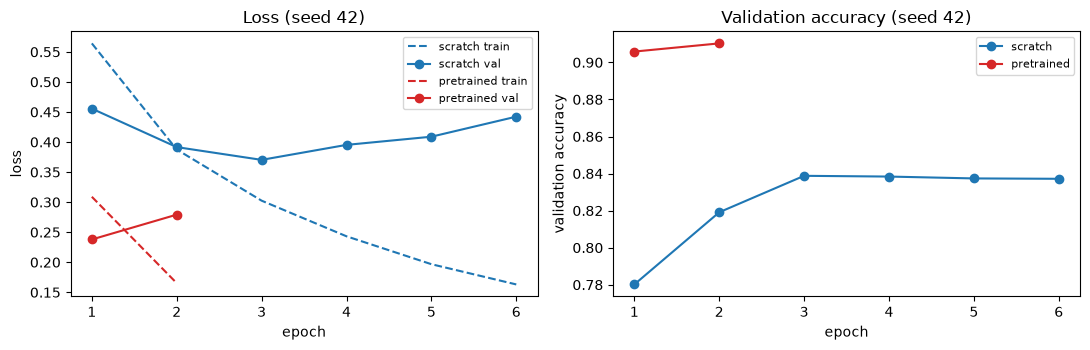

scratch
 epoch  train_loss  val_loss  val_acc
     1      0.5641    0.4556   0.7802
     2      0.3876    0.3916   0.8191
     3      0.3024    0.3703   0.8388
     4      0.2432    0.3953   0.8384
     5      0.1968    0.4089   0.8374
     6      0.1631    0.4422   0.8372
pretrained
 epoch  train_loss  val_loss  val_acc
     1      0.3089    0.2379   0.9058
     2      0.1652    0.2792   0.9103


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for r, c in [(scratch42, "C0"), (ft42, "C3")]:
    h = pd.DataFrame(r["hist"])
    ax[0].plot(h.epoch, h.train_loss, "--", c=c, label=f"{r['model']} train")
    ax[0].plot(h.epoch, h.val_loss, "-o", c=c, label=f"{r['model']} val")
    ax[1].plot(h.epoch, h.val_acc, "-o", c=c, label=r["model"])
ax[0].set(xlabel="epoch", ylabel="loss", title="Loss (seed 42)"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy (seed 42)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/learning_curves.png", dpi=120); plt.show()
for r in (scratch42, ft42):
    print(r["model"], pd.DataFrame(r["hist"]).round(4).to_string(index=False), sep="\n")

## 4. Exp 2 — Frozen encoder so với fine-tuning

Frozen: chạy DistilBERT pretrained (không cập nhật) **một lần** trên mọi review, lưu vector [CLS] và mean của token thật, rồi chỉ train head (dropout + Linear, 1 538 tham số) bằng Adam lr 1e-3, 30 epoch, chọn epoch theo validation loss. Thời gian train = thời gian trích feature của train + validation cộng thời gian train head.

In [7]:
encoder = pc.PretrainedClassifier().encoder
feats, ext_time = {}, {}
for k in ["train", "val", "test"]:
    t0 = time.time()
    feats[k] = pc.extract_features(encoder, ids[k], 256)
    ext_time[k] = time.time() - t0
print({k: f"{v:.0f}s" for k, v in ext_time.items()})

def run_frozen(pool, frac=1.0, seed=42):
    j = 0 if pool == "cls" else 1
    idx = subset(frac)
    t0 = time.time()
    head, hist = pc.train_head(feats["train"][j][idx], y["train"][idx], feats["val"][j], y["val"], seed=seed)
    t_head = time.time() - t0
    p = pc.head_proba(head, feats["test"][j])
    return {"model": f"frozen ({pool})", "seed": seed, "frac": frac, "T": 256, "n_train": len(idx),
            "params": sum(q.numel() for q in head.parameters()),
            "train_time": ext_time["train"] * frac + ext_time["val"] + t_head, "head_time": t_head,
            **pc.metrics(y["test"], p), "proba": p, "head": head, "hist": hist}

frozen = {pool: run_frozen(pool) for pool in ["cls", "mean"]}
exp2 = [frozen["cls"], frozen["mean"]] + [r for r in exp1 if r["model"] == "pretrained"]
tab2 = summary(exp2, "model")
tab2.insert(0, "encoder trainable?", ["No", "No", "Yes"])
tab2["trainable params"] = [1538, 1538, ft42["params"]]
for r in frozen.values():
    for c in ("accuracy", "precision", "recall", "f1", "train_time"):
        log("Exp2", r["model"], c, float(r[c]))
tab2

{'train': '223s', 'val': '56s', 'test': '281s'}


,encoder trainable?,accuracy,precision,recall,f1,train_time,params,runs,trainable params
model,,,,,,,,,
frozen (cls),No,0.8526 ± nan,0.8671,0.8328,0.8496 ± nan,290.0590,1538,1,1538
frozen (mean),No,0.8586 ± nan,0.8730,0.8394,0.8559 ± nan,288.6074,1538,1,1538
pretrained,Yes,0.9111 ± 0.0023,0.9085,0.9146,0.9114 ± 0.0022,484.4285,66364418,3,66364418


## 5. Exp 3 — Lượng training data (10 / 25 / 50 / 100%)

Subset lấy ngẫu nhiên (seed 42) và lồng nhau. Validation và test giữ nguyên. Pretrained và from scratch chạy 1 seed cho 10–50%; điểm 100% là trung bình 3 seed của Exp 1. Frozen (CLS và mean) dùng lại feature đã cache.

In [8]:
exp3 = []
for frac in [0.1, 0.25, 0.5]:
    exp3.append(run("scratch", frac=frac))
    exp3.append(run("pretrained", frac=frac))
    for pool in ["cls", "mean"]:
        exp3.append(run_frozen(pool, frac=frac))
exp3 += [r for r in exp1] + [frozen["cls"], frozen["mean"]]
d3 = pd.DataFrame([{k: r[k] for k in ("model", "seed", "frac", "n_train", "accuracy", "f1", "train_time")} for r in exp3])
tab3 = d3.groupby(["model", "frac"]).agg(n_train=("n_train", "first"), accuracy=("accuracy", "mean"),
                                         f1=("f1", "mean"), train_time=("train_time", "mean"), runs=("seed", "size")).round(4)
for (m, f), r in tab3.iterrows():
    log("Exp3", f"{m} frac={f}", "accuracy", r.accuracy); log("Exp3", f"{m} frac={f}", "f1", r.f1)
tab3

scratch | seed 42 | 10% train (1992) | T = 256
  epoch 1: train loss 0.6915 | val loss 0.6648 | val acc 0.6270 | 1s
  epoch 2: train loss 0.6533 | val loss 0.7382 | val acc 0.5192 | 1s
  epoch 3: train loss 0.6160 | val loss 0.5985 | val acc 0.6792 | 1s
  epoch 4: train loss 0.5583 | val loss 0.5734 | val acc 0.7027 | 1s
  epoch 5: train loss 0.5065 | val loss 0.5580 | val acc 0.7141 | 1s
  epoch 6: train loss 0.4759 | val loss 0.5620 | val acc 0.7197 | 1s
  → test acc 0.7115 | F1 0.7076 | train 4s | peak 156 MB | skipped 0
pretrained | seed 42 | 10% train (1992) | T = 256
  epoch 1: train loss 0.4456 | val loss 0.2942 | val acc 0.8745 | 82s
  epoch 2: train loss 0.2132 | val loss 0.2943 | val acc 0.8836 | 97s
  → test acc 0.8763 | F1 0.8774 | train 49s | peak 1954 MB | skipped 0
scratch | seed 42 | 25% train (4981) | T = 256
  epoch 1: train loss 0.6725 | val loss 0.6060 | val acc 0.6764 | 2s
  epoch 2: train loss 0.5675 | val loss 0.5089 | val acc 0.7503 | 2s
  epoch 3: train loss 0.

n_train  accuracy      f1  train_time  runs
model         frac                                             
frozen (cls)  0.10     1992    0.8367  0.8334     79.9553     1
              0.25     4981    0.8449  0.8403    115.3078     1
              0.50     9962    0.8502  0.8483    175.4187     1
              1.00    19923    0.8526  0.8496    290.0590     1
frozen (mean) 0.10     1992    0.8374  0.8339     79.9461     1
              0.25     4981    0.8486  0.8458    115.4894     1
              0.50     9962    0.8542  0.8527    173.9673     1
              1.00    19923    0.8586  0.8559    288.6074     1
pretrained    0.10     1992    0.8763  0.8774     49.1583     1
              0.25     4981    0.8942  0.8957    121.5893     1
              0.50     9962    0.8973  0.9010    242.5616     1
              1.00    19923    0.9111  0.9114    484.4285     3
scratch       0.10     1992    0.7115  0.7076      3.6397     1
              0.25     4981    0.7784  0.7639      8.9087     1
              0.50     9962    0.8134  0.8169     17.9112     1
              1.00    19923    0.8350  0.8352     33.0790     3

In [9]:
acc3 = tab3.accuracy.unstack(0)
print("Accuracy theo % data:"); print(acc3.round(4))
print("\nGiảm khi đi từ 100% xuống 10% (điểm accuracy):")
print((acc3.loc[1.0] - acc3.loc[0.1]).round(4))
print("\nKhoảng cách pretrained − scratch:")
print((acc3["pretrained"] - acc3["scratch"]).round(4))

Accuracy theo % data:
model  frozen (cls)  frozen (mean)  pretrained  scratch
frac                                                   
0.10         0.8367         0.8374      0.8763   0.7115
0.25         0.8449         0.8486      0.8942   0.7784
0.50         0.8502         0.8542      0.8973   0.8134
1.00         0.8526         0.8586      0.9111   0.8350

Giảm khi đi từ 100% xuống 10% (điểm accuracy):
model
frozen (cls)     0.0159
frozen (mean)    0.0212
pretrained       0.0348
scratch          0.1235
dtype: float64

Khoảng cách pretrained − scratch:
frac
0.10    0.1648
0.25    0.1158
0.50    0.0839
1.00    0.0761
dtype: float64


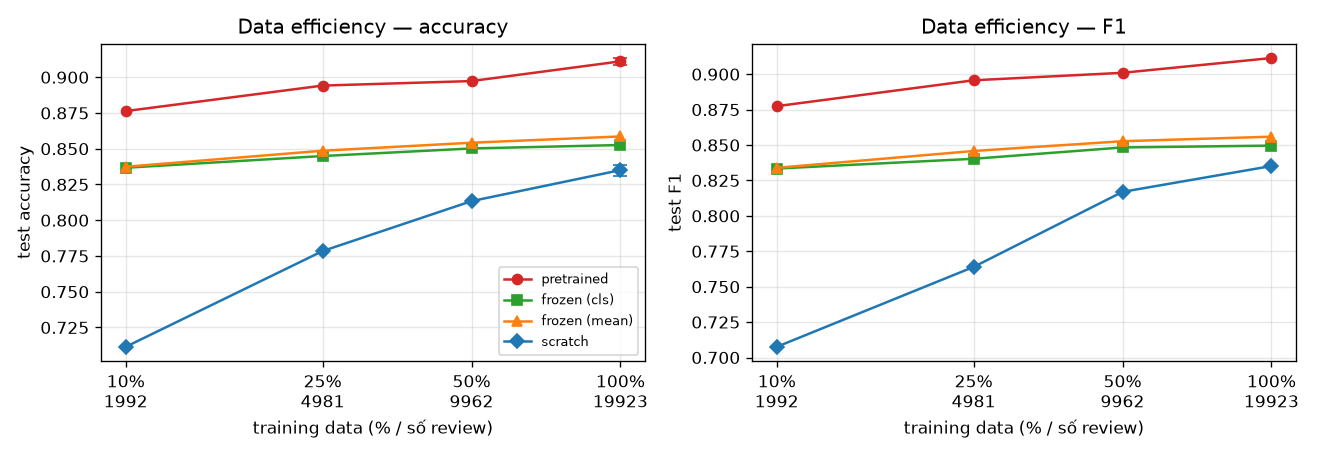

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
style = {"pretrained": ("C3", "o"), "frozen (cls)": ("C2", "s"), "frozen (mean)": ("C1", "^"), "scratch": ("C0", "D")}
for m, (c, mk) in style.items():
    t = tab3.loc[m]
    x = t.n_train.values
    ax[0].plot(x, t.accuracy.values, marker=mk, c=c, label=m)
    ax[1].plot(x, t.f1.values, marker=mk, c=c, label=m)
    if m in ("pretrained", "scratch"):                    # độ lệch giữa 3 seed ở 100%
        v = d3[(d3.model == m) & (d3.frac == 1.0)].accuracy
        ax[0].errorbar(x[-1], v.mean(), yerr=v.std(), c=c, capsize=4)
for a, name in zip(ax, ["accuracy", "F1"]):
    a.set_xscale("log"); a.xaxis.set_minor_locator(NullLocator()); a.set_xticks(tab3.loc["scratch"].n_train.values)
    a.set_xticklabels([f"{f:.0%}\n{n}" for f, n in zip([0.1, 0.25, 0.5, 1.0], tab3.loc["scratch"].n_train.values)])
    a.set(xlabel="training data (% / số review)", ylabel=f"test {name}", title=f"Data efficiency — {name}")
    a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/data_efficiency.png", dpi=120); plt.show()

## 6. Exp 4 — Max sequence length 64 / 128 / 256

Pretrained fine-tuning, seed 42, 100% data. Điểm T = 256 lấy từ Exp 1 (seed 42). Bộ nhớ là đỉnh `torch.cuda.max_memory_allocated` trong lúc train (gồm trọng số, optimizer state, activation).

In [11]:
exp4 = [run("pretrained", T=T) for T in [64, 128]] + [ft42]
tab4 = pd.DataFrame([{"max length": r["T"], "accuracy": r["accuracy"], "f1": r["f1"], "train time (s)": r["train_time"],
                      "test time (s)": r["test_time"], "peak GPU mem (MB)": r["peak_mem_mb"],
                      "% review bị cắt": np.mean(n_tok > r["T"])} for r in exp4]).set_index("max length").round(4)
for T, r in tab4.iterrows():
    for c in tab4.columns:
        log("Exp4", f"T={T}", c, float(r[c]))
tab4

pretrained | seed 42 | 100% train (19923) | T = 64
  epoch 1: train loss 0.4559 | val loss 0.3741 | val acc 0.8285 | 102s
  epoch 2: train loss 0.2957 | val loss 0.3982 | val acc 0.8358 | 101s
  → test acc 0.8218 | F1 0.8206 | train 196s | peak 1345 MB | skipped 21
pretrained | seed 42 | 100% train (19923) | T = 128
  epoch 1: train loss 0.3735 | val loss 0.2892 | val acc 0.8745 | 148s
  epoch 2: train loss 0.2180 | val loss 0.3254 | val acc 0.8773 | 148s
  → test acc 0.8749 | F1 0.8738 | train 282s | peak 1548 MB | skipped 63


,accuracy,f1,train time (s),test time (s),peak GPU mem (MB),% review bị cắt
max length,,,,,,
64,0.8218,0.8206,196.3891,18.6463,1344.9800,0.9788
128,0.8749,0.8738,281.9496,34.6844,1547.6909,0.8781
256,0.9104,0.9095,483.9585,232.4283,1950.7378,0.4120


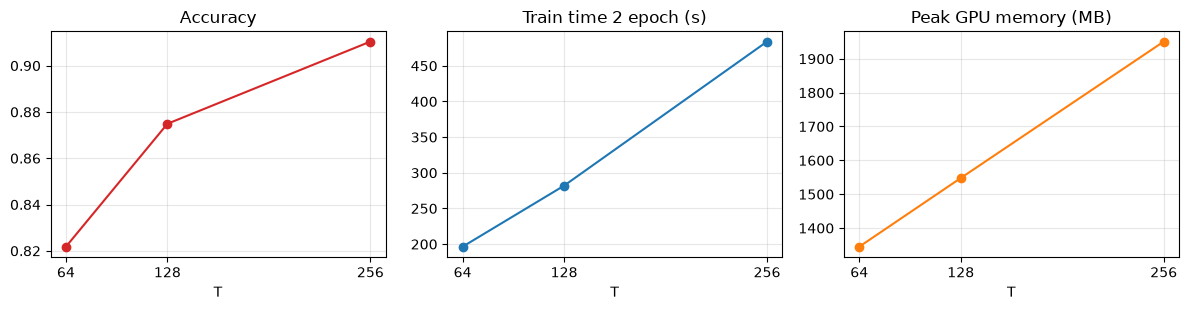

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(tab4.index, tab4.accuracy, "-o", c="C3"); ax[0].set(title="Accuracy", xlabel="T")
ax[1].plot(tab4.index, tab4["train time (s)"], "-o", c="C0"); ax[1].set(title="Train time 2 epoch (s)", xlabel="T")
ax[2].plot(tab4.index, tab4["peak GPU mem (MB)"], "-o", c="C1"); ax[2].set(title="Peak GPU memory (MB)", xlabel="T")
for a in ax:
    a.set_xticks(tab4.index); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("images/sequence_length.png", dpi=120); plt.show()

## 7. Exp 5 — Domain shift

- **Domain A (in-domain):** IMDb, review phim.
- **Domain B (out-of-domain):** Yelp (review nhà hàng / dịch vụ) và Amazon (review sản phẩm). Mỗi bộ lấy 2 000 mẫu cân bằng nhãn từ tập test gốc.

Không train lại: dùng đúng 3 model đã train trên IMDb (seed 42), T = 256.

In [13]:
dom = {name: pc.load_domain(name) for name in ["yelp", "amazon"]}
for name, d in dom.items():
    d_ids = pc.encode(tokenizer, d.text)
    ids[name], y[name] = d_ids, d.label.values
    print(f"{name}: {len(d)} mẫu, median {np.median([len(x) for x in d_ids]):.0f} token | ví dụ: {d.text[0][:150]}…")
    feats[name] = pc.extract_features(encoder, d_ids, 256)

rows5 = []
for name in ["test", "yelp", "amazon"]:
    preds = {"scratch": pc.predict_proba(scratch42["model_obj"], ids[name], 256),
             "frozen (cls)": pc.head_proba(frozen["cls"]["head"], feats[name][0]),
             "frozen (mean)": pc.head_proba(frozen["mean"]["head"], feats[name][1]),
             "pretrained": pc.predict_proba(ft42["model_obj"], ids[name], 256)}
    for m, p in preds.items():
        rows5.append({"domain": "IMDb (in-domain)" if name == "test" else name, "model": m, **pc.metrics(y[name], p),
                      "mean confidence": np.maximum(p, 1 - p).mean()})
tab5 = pd.DataFrame(rows5).set_index(["model", "domain"]).sort_index().round(4)
for (m, d), r in tab5.iterrows():
    for c in tab5.columns:
        log("Exp5", f"{m} | {d}", c, float(r[c]))
tab5

yelp: 2000 mẫu, median 125 token | ví dụ: They say what you see is what you get and after seeing her amazing hair and makeup I knew I had to have her do my makeup/hair for my wedding. She was …
amazon: 2000 mẫu, median 94 token | ví dụ: One happy camper!. Let's see...$5 cheaper than the local retailer AND free shipping...how can you go wrong??? On top of all that, the optional "ball h…


accuracy  precision  recall      f1  \
model         domain                                                  
frozen (cls)  IMDb (in-domain)    0.8526     0.8671  0.8328  0.8496   
              amazon              0.8735     0.8514  0.9050  0.8774   
              yelp                0.8750     0.8447  0.9190  0.8803   
frozen (mean) IMDb (in-domain)    0.8586     0.8730  0.8394  0.8559   
              amazon              0.8595     0.8207  0.9200  0.8675   
              yelp                0.8570     0.8046  0.9430  0.8683   
pretrained    IMDb (in-domain)    0.9104     0.9191  0.9001  0.9095   
              amazon              0.9265     0.9169  0.9380  0.9273   
              yelp                0.9235     0.9206  0.9270  0.9238   
scratch       IMDb (in-domain)    0.8316     0.8259  0.8403  0.8330   
              amazon              0.7845     0.7565  0.8390  0.7956   
              yelp                0.7960     0.7741  0.8360  0.8038   

                                mean confidence  
model         domain                             
frozen (cls)  IMDb (in-domain)           0.8488  
              amazon                     0.8787  
              yelp                       0.8698  
frozen (mean) IMDb (in-domain)           0.8495  
              amazon                     0.8754  
              yelp                       0.8608  
pretrained    IMDb (in-domain)           0.9246  
              amazon                     0.9224  
              yelp                       0.9022  
scratch       IMDb (in-domain)           0.8736  
              amazon                     0.8797  
              yelp                       0.8608

In [14]:
acc5 = tab5.accuracy.unstack()
print("Accuracy:"); print(acc5)
print("\nOut-of-domain − in-domain:")
print(acc5[["amazon", "yelp"]].sub(acc5["IMDb (in-domain)"], axis=0).round(4))

Accuracy:
domain         IMDb (in-domain)  amazon    yelp
model                                          
frozen (cls)             0.8526  0.8735  0.8750
frozen (mean)            0.8586  0.8595  0.8570
pretrained               0.9104  0.9265  0.9235
scratch                  0.8316  0.7845  0.7960

Out-of-domain − in-domain:
domain         amazon    yelp
model                        
frozen (cls)   0.0209  0.0224
frozen (mean)  0.0009 -0.0016
pretrained     0.0161  0.0131
scratch       -0.0471 -0.0356


## 8. Application — sentiment classification (pretrained fine-tuned, seed 42)

In [15]:
p_ft, y_te = ft42["proba"], y["test"]
pred_ft = (p_ft > 0.5).astype(int)
app = pd.DataFrame({m: pc.metrics(y_te, p) for m, p in
                    [("scratch", scratch42["proba"]), ("frozen (cls)", frozen["cls"]["proba"]),
                     ("frozen (mean)", frozen["mean"]["proba"]), ("pretrained", p_ft)]}).T.round(4)
app

,accuracy,precision,recall,f1
scratch,0.8316,0.8259,0.8403,0.8330
frozen (cls),0.8526,0.8671,0.8328,0.8496
frozen (mean),0.8586,0.8730,0.8394,0.8559
pretrained,0.9104,0.9191,0.9001,0.9095


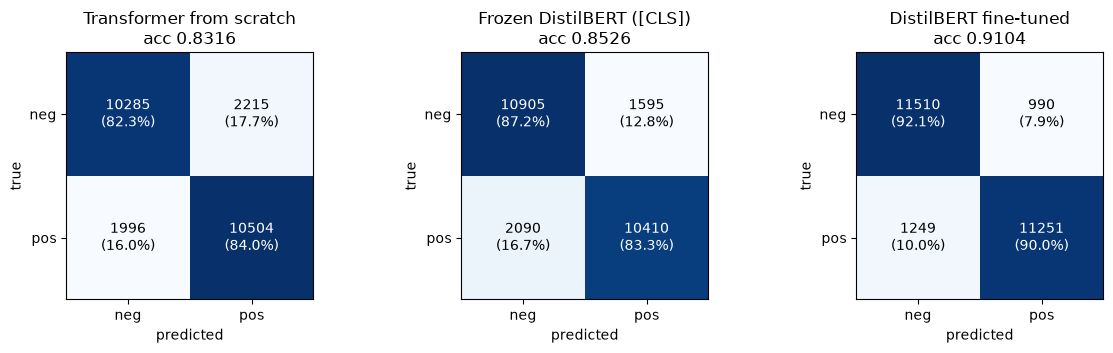

Fine-tuned: TN, FP, FN, TP = [11510   990  1249 11251]


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, (m, p) in zip(ax, [("Transformer from scratch", scratch42["proba"]), ("Frozen DistilBERT ([CLS])", frozen["cls"]["proba"]),
                          ("DistilBERT fine-tuned", p_ft)]):
    cm = confusion_matrix(y_te, p > 0.5)
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["neg", "pos"], yticklabels=["neg", "pos"],
          xlabel="predicted", ylabel="true", title=f"{m}\nacc {np.mean((p > 0.5) == y_te):.4f}")
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()
cm = confusion_matrix(y_te, pred_ft)
print("Fine-tuned: TN, FP, FN, TP =", cm.ravel())
for k, v in zip(["TN", "FP", "FN", "TP"], cm.ravel()):
    log("Application", "pretrained seed=42", k, int(v))

In [17]:
own = ["This movie was absolutely wonderful, I loved every minute.",
       "Not bad at all, actually one of the better films this year.",
       "I expected to hate it, but it turned out to be great.",
       "It was great... if you enjoy falling asleep.",
       "The acting was fine but the plot made no sense whatsoever.",
       "A masterpiece of boredom.",
       "Oh great, another two hours of my life I will never get back.",
       "The food was cold and the waiter was rude.",
       "Battery life is excellent and it charges quickly.",
       "Phim rất hay, diễn viên đóng tuyệt vời."]
own_ids = pc.encode(tokenizer, own)
p_own = {"scratch": pc.predict_proba(scratch42["model_obj"], own_ids, 256),
         "pretrained": pc.predict_proba(ft42["model_obj"], own_ids, 256)}
pd.set_option("display.max_colwidth", 80)
pd.DataFrame({"text": own, "P(pos) scratch": p_own["scratch"].round(3), "P(pos) fine-tuned": p_own["pretrained"].round(3)})

,text,P(pos) scratch,P(pos) fine-tuned
0,"This movie was absolutely wonderful, I loved every minute.",1.000,0.996
1,"Not bad at all, actually one of the better films this year.",0.021,0.942
2,"I expected to hate it, but it turned out to be great.",0.998,0.940
3,It was great... if you enjoy falling asleep.,0.996,0.973
4,The acting was fine but the plot made no sense whatsoever.,0.001,0.009
5,A masterpiece of boredom.,0.995,0.853
6,"Oh great, another two hours of my life I will never get back.",0.999,0.712
7,The food was cold and the waiter was rude.,0.237,0.045
8,Battery life is excellent and it charges quickly.,1.000,0.943
9,"Phim rất hay, diễn viên đóng tuyệt vời.",0.966,0.647


## 9. Confidence analysis

`confidence = max(softmax(logits))`. Chia ba nhóm: **High** ≥ 0.95, **Medium** 0.75–0.95, **Low** < 0.75.

In [18]:
def conf_table(p, yy):
    conf = np.maximum(p, 1 - p)
    correct = (p > 0.5) == yy
    grp = pd.cut(conf, [0.5, 0.75, 0.95, 1.0001], labels=["Low (<0.75)", "Medium (0.75–0.95)", "High (≥0.95)"], include_lowest=True)
    t = pd.DataFrame({"group": grp, "correct": correct, "conf": conf}).groupby("group", observed=False).agg(
        n=("correct", "size"), accuracy=("correct", "mean"), mean_conf=("conf", "mean"), errors=("correct", lambda c: int((~c).sum())))
    t["% mẫu"] = t.n / t.n.sum()
    t["% lỗi"] = t.errors / t.errors.sum()
    return t.round(4)

def ece(p, yy, bins=10):
    conf = np.maximum(p, 1 - p); correct = (p > 0.5) == yy
    edges = np.linspace(0.5, 1, bins + 1); e = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

for name, p in [("pretrained fine-tuned", p_ft), ("scratch", scratch42["proba"]), ("frozen (cls)", frozen["cls"]["proba"])]:
    t = conf_table(p, y_te)
    print(f"\n{name}: ECE = {ece(p, y_te):.4f}"); print(t)
    log("Confidence", name, "ECE", ece(p, y_te))
    for g, r in t.iterrows():
        log("Confidence", f"{name} | {g}", "accuracy", r.accuracy); log("Confidence", f"{name} | {g}", "n", int(r.n))
wrong = (pred_ft != y_te)
conf_ft = np.maximum(p_ft, 1 - p_ft)
print(f"\nFine-tuned: {wrong.sum()} lỗi; {np.mean(conf_ft[wrong] > 0.95):.1%} lỗi có confidence > 0.95, "
      f"{np.mean(conf_ft[wrong] > 0.99):.1%} lỗi có confidence > 0.99")


pretrained fine-tuned: ECE = 0.0142
                        n  accuracy  mean_conf  errors   % mẫu   % lỗi
group                                                                 
Low (<0.75)          2605    0.6138     0.6346    1006  0.1042  0.4493
Medium (0.75–0.95)   5538    0.8346     0.8781     916  0.2215  0.4091
High (≥0.95)        16857    0.9812     0.9847     317  0.6743  0.1416

scratch: ECE = 0.0429
                        n  accuracy  mean_conf  errors   % mẫu   % lỗi
group                                                                 
Low (<0.75)          5131    0.5913     0.6323    2097  0.2052  0.4980
Medium (0.75–0.95)   8421    0.8011     0.8711    1675  0.3368  0.3978
High (≥0.95)        11448    0.9617     0.9835     439  0.4579  0.1043

frozen (cls): ECE = 0.0068
                        n  accuracy  mean_conf  errors   % mẫu   % lỗi
group                                                                 
Low (<0.75)          6202    0.6324     0.6304    2280  0.24

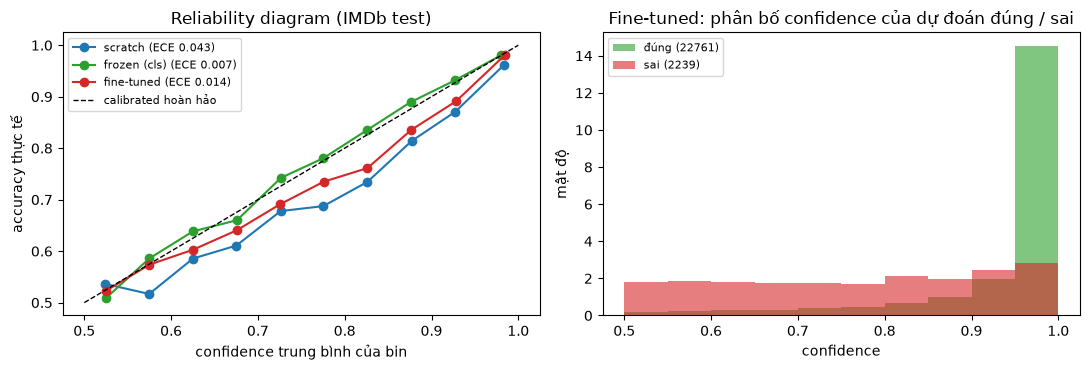

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0.5, 1, 11)
for name, p, c in [("scratch", scratch42["proba"], "C0"), ("frozen (cls)", frozen["cls"]["proba"], "C2"), ("fine-tuned", p_ft, "C3")]:
    conf = np.maximum(p, 1 - p); correct = (p > 0.5) == y_te
    idx = np.clip(np.digitize(conf, bins) - 1, 0, 9)
    xs = [conf[idx == b].mean() for b in range(10) if (idx == b).sum() > 20]
    ys = [correct[idx == b].mean() for b in range(10) if (idx == b).sum() > 20]
    ax[0].plot(xs, ys, "-o", c=c, label=f"{name} (ECE {ece(p, y_te):.3f})")
ax[0].plot([0.5, 1], [0.5, 1], "k--", lw=1, label="calibrated hoàn hảo")
ax[0].set(xlabel="confidence trung bình của bin", ylabel="accuracy thực tế", title="Reliability diagram (IMDb test)"); ax[0].legend(fontsize=8)
ax[1].hist(conf_ft[~wrong], bins=bins, alpha=0.6, label=f"đúng ({(~wrong).sum()})", color="C2", density=True)
ax[1].hist(conf_ft[wrong], bins=bins, alpha=0.6, label=f"sai ({wrong.sum()})", color="C3", density=True)
ax[1].set(xlabel="confidence", ylabel="mật độ", title="Fine-tuned: phân bố confidence của dự đoán đúng / sai"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/confidence_analysis.png", dpi=120); plt.show()

## 10. Error analysis (fine-tuned, seed 42)

In [20]:
te = data["test"].assign(p=p_ft, pred=pred_ft, conf=conf_ft, n_tok=[len(x) for x in ids["test"]])
te["truncated"] = te.n_tok > 256
err = te[te.pred != te.label]
print(f"Lỗi: {len(err)} (FP {((err.pred == 1)).sum()}, FN {((err.pred == 0)).sum()})")
print(f"Tỉ lệ lỗi: review bị cắt ở 256 token {1 - (te[te.truncated].pred == te[te.truncated].label).mean():.4f}, "
      f"không bị cắt {1 - (te[~te.truncated].pred == te[~te.truncated].label).mean():.4f}")
te["len_bin"] = pd.qcut(te.n_tok, 4, labels=["Q1 ngắn", "Q2", "Q3", "Q4 dài"])
print(te.groupby("len_bin", observed=False).apply(lambda g: pd.Series({"token median": g.n_tok.median(), "accuracy": (g.pred == g.label).mean()})).round(4))

def show(df, title):
    print(f"\n{'=' * 20} {title}")
    for i, r in df.iterrows():
        print(f"\n[#{i}] true {r.label} | pred {r.pred} | P(pos) {r.p:.4f} | conf {r.conf:.4f} | {r.n_tok} token{' (bị cắt)' if r.truncated else ''}")
        print(r.text[:900] + ("…" if len(r.text) > 900 else ""))

rng = np.random.default_rng(1)
fp, fn = err[err.pred == 1], err[err.pred == 0]
show(fp.sample(4, random_state=1), "FALSE POSITIVES (ngẫu nhiên)")
show(fn.sample(4, random_state=1), "FALSE NEGATIVES (ngẫu nhiên)")
show(err.sort_values("conf", ascending=False).head(4), "SAI NHƯNG RẤT TỰ TIN")

Lỗi: 2239 (FP 990, FN 1249)
Tỉ lệ lỗi: review bị cắt ở 256 token 0.1237, không bị cắt 0.0667
         token median  accuracy
len_bin                        
Q1 ngắn         128.0    0.9309
Q2              184.0    0.9372
Q3              269.0    0.9166
Q4 dài          509.5    0.8570

==================== FALSE POSITIVES (ngẫu nhiên)

[#4116] true 0 | pred 1 | P(pos) 0.6553 | conf 0.6553 | 178 token
I bought this Chuck Norris DVD knowing that it was one of his earliest films, and it shows. We all know that he will never win an Oscar for his acting, but that's not what we watch him for. Although there have been a few earthquakes in California since this movie was made, there never was any desert or hills between Hwy.99 and I 5. Billy was supposedly crossing over from 99 to 5 along 120, a distance of less that 15 miles. I wish that the writers, producers and directors of these movies would, at least, look at a map. As a truck driver who spends a lot of time in California, I could tell ri

Đối chiếu: các lỗi của model fine-tuned có phải cũng là lỗi của model from scratch không?

In [21]:
pred_sc = scratch42["proba"] > 0.5
both = pd.crosstab(pd.Series(pred_ft == y_te, name="fine-tuned đúng"), pd.Series(pred_sc == y_te, name="scratch đúng"))
print(both)
print(f"\nTrong {wrong.sum()} lỗi của fine-tuned, scratch cũng sai {np.mean(pred_sc[wrong] != y_te[wrong]):.1%}")

scratch đúng     False  True 
fine-tuned đúng              
False             1295    944
True              2916  19845

Trong 2239 lỗi của fine-tuned, scratch cũng sai 57.8%


## 11. Lưu kết quả

In [22]:
pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng → results.csv | tổng thời gian notebook:", f"{(time.time() - t_all) / 60:.1f} phút")
print("skipped steps (NaN) tổng:", int(sum(r["value"] for r in RESULTS if r["metric"] == "skipped_steps")),
      "| GPU retries:", sum(1 for r in RESULTS if r["experiment"] == "GPU retries"))

285 dòng → results.csv | tổng thời gian notebook: 114.3 phút
skipped steps (NaN) tổng: 85 | GPU retries: 0
